In [1]:
import mindmap as mm

subject = 1
reader  = mm.io.dataset_reader(config = "../../../papers/simf/configuration.yml")

data = reader(subject, "length1000", "weight1000", "eeg")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg
- weight1000
- length1000
Missing objects:


In [8]:
mm.viz.plot_leadfield(data["eeg"], data["fwd1000"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:35607/index.html?ui=P_0x7c579e643810_3&reconnect=auto" class="pyvi…

In [1]:
import numpy as np
from tvb.simulator.lab import *
from jr_models import habJansenRit
import pyvista as pv
import matplotlib.pyplot as plt 
from scipy.spatial import cKDTree

In [125]:
def plot_graph(points, adjacency):
    """
    Parameters
    ----------
    points: np.array (N,3) 
    lines: np.array (N,2)
    """

    P = pv.PolyData(points)
    A1 = adjacency > 0
    A2 = adjacency < 0

    lines1 = []
    lines2 = []
    for i in range(len(A1)):
        for j in range(i, len(A1)):
            if A1[i,j]:
                lines1 += [points[i], points[j]]
            if A2[i,j]:
                lines2 += [points[i], points[j]]
    lines1 = np.array(lines1)
    lines2 = np.array(lines2)

    p = pv.Plotter()
    p.add_mesh(P)
    if len(lines1) > 0:
        p.add_lines(lines1, color="green", width=0.05)
    if len(lines2) > 0:
        p.add_lines(lines2, color="red", width=0.01)

    return p

def plot_graph_activity(conn, time, data, dt=0.1, show_max=False):

    clim = [np.min(np.abs(data)), np.max(np.abs(data))]

    p = pv.Plotter()

    def create_mesh(t):
        points = pv.PolyData(conn.centres)
        points["activity"] = data[int((t-time[0])/dt),:]
        p.add_mesh(points, point_size=10,render_points_as_spheres=True, clim=clim)

    p.add_slider_widget(create_mesh, [time[0], time[-1]], title="time [ms]")

    if show_max:
        # nodes with biggest spikes
        maxis = np.max(data, axis=0)
        indices = np.argsort(maxis)[-1]

        p.add_mesh(pv.PolyData(conn.centres[indices]), point_size=20)
        
    p.show()


def generate_ring_graph(N):
    # 1. Generate node positions on a unit circle
    angles = np.linspace(0, 2*np.pi, N, endpoint=False)

    x_coords = np.cos(angles)
    y_coords = np.sin(angles)
    z_coords = np.zeros_like(angles)

    centres = np.vstack((x_coords, y_coords, z_coords)).T
    labels  = np.array([f"{i}" for i in range(N)])

    # 2. Generate the adjacency matrix
    weights = np.zeros((N,N), dtype=int)

    for i in range(N):
        prev_node = (i - 1 + N) % N
        next_node = (i + 1) % N 

        weights[i, prev_node] = 1
        weights[i, next_node] = 1

    lengths = weights*10

    return centres, labels, weights, lengths

def generate_sphere_graph(N, k_neighbors=4):
    # 1. Generate node postions on a unit sphere
    centres = []
    golden_angle = np.pi * (3.0 - np.sqrt(5.0))

    for i in range(N):
        y      = 1 - (i / float(N))
        radius = np.sqrt(1 - y * y)
        theta  = i * golden_angle

        x = radius * np.cos(theta)
        z = radius * np.sin(theta)

        centres.append([x,y,z])

    centres = np.array(centres)
    labels  = np.array([f"{i}" for i in range(N)])

    # 2. Generate adjacency matrix by finding k-nearest neighbors
    tree = cKDTree(centres)

    weights = np.zeros((N,N), dtype=int)
    lengths = np.zeros((N,N), dtype=int)

    distances, indices = tree.query(centres, k=k_neighbors + 1)

    for i in range(N):
        for neighbor_index, dist in zip(indices[i], distances[i]):
            if i != neighbor_index:
                weights[i, neighbor_index] = 1
                weights[neighbor_index, i] = 1
                lengths[i, neighbor_index] = dist
                lengths[neighbor_index, i] = dist

    return centres, labels, weights, lengths

centres, labels, weights, lengths = generate_sphere_graph(1000)
speed   = np.array([3])

plot_graph(centres, weights).show()

Widget(value='<iframe src="http://localhost:35079/index.html?ui=P_0x712d6a19c7d0_12&reconnect=auto" class="pyv…

In [108]:
def build_connectvitiy(weights, lengths, labels, centres, speed):
    s_conn = connectivity.Connectivity(
        weights = weights,
        tract_lengths= lengths,
    )

    s_conn.weights       = s_conn.weights - s_conn.weights*np.eye(s_conn.weights.shape[0])
    s_conn.weights       = s_conn.scaled_weights(mode='tract')
    s_conn.region_labels = labels
    s_conn.centres       = centres
    s_conn.speed         = speed

    s_conn.configure()

    return s_conn

In [109]:
def run_hab_sim(eta=0.01, tau_d=10, mu=0.03, gc_val=10, stimulations = [([0], 0.03, 180000)], integration="det"):
    '''defines the separate runction to run the simulation with the model defined above
    input: parameter'''

    s_conn = build_connectvitiy(weights, lengths, labels, centres, speed)
    N      = s_conn.number_of_regions

    jrm_hab = habJansenRit(
        v0    = np.array([6.]), 
        eta   = np.array([eta]),
        tau_d = np.array([tau_d]),
    )
    
    if integration == 'det':
        your_integrator = integrators.HeunDeterministic(dt=0.1)
        
    if integration == 'stoch':
        sigma         = np.zeros(9) 
        sigma[3]      = 0.00000025
        your_integrator = integrators.HeunStochastic(dt=0.1, noise=noise.Additive(nsig=sigma))
        
    sim = simulator.Simulator(
        connectivity       = s_conn,
        model              = jrm_hab,
        coupling           = coupling.SigmoidalJansenRit(a=np.array([gc_val]),r=np.array([0.56])),
        integrator         = your_integrator,
        monitors           = [monitors.SubSample(period=1)],
        simulation_length  = 10000
    )
    
    sim.model.mu = np.array([mu])
    sim.configure()

    # run the 'habituation' simulation
    y0 = np.zeros(shape=(0,N))
    y1 = np.zeros(shape=(0,N))
    y2 = np.zeros(shape=(0,N))
    C  = np.zeros(shape=(0,N))

    for stim in stimulations:
        targs, val, t = stim
        stim_mu = val if val > 0 else mu
        print("mu = ", stim_mu)

        # update simulation parameters
        sim.simulation_length = t
        sim.model.mu = np.ones(N)*mu
        sim.model.mu[targs] = stim_mu

        # run section
        output = sim.run()
        
        ssamp = output[0][1]
        y0 = np.vstack([y0, ssamp[:,0,:,0]])
        y1 = np.vstack([y1, ssamp[:,1,:,0]])
        y2 = np.vstack([y2, ssamp[:,2,:,0]])
        C  = np.vstack([C, ssamp[:,3,:,0]])

    PSP = y1 - y2
    
    return PSP, C, y0

In [110]:
print("Running turbo tuning ...")

eta = 1
tau_d = 1
mu = 0.1
gc_val = 100

stimulations = [([0], mu, 4000)]
stimulations = stimulation  = [([0], 0, 2000), ([8], 0.3, 100), ([0], 0, 2000)]

hab_results = run_hab_sim(
    eta = eta,
    tau_d = tau_d,
    mu = mu,
    gc_val = gc_val,
    stimulations = stimulations, 
    integration="det"
)

Running turbo tuning ...
mu =  0.1
2025-08-22 10:44:21,118 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/numba/np/ufunc/gufunc.py:261: RuntimeWarning: overflow encountered in _numba_dfun_habjr
  return self.ufunc(*args, **kwargs)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/tvb/simulator/coupling.py:372: RuntimeWarning: overflow encountered in exp
  (self.cmax - self.cmin) / (1.0 + numpy.exp(self.r * (self.midpoint - (x_j[:, 0] - x_j[:, 1]))))


mu =  0.3
2025-08-22 10:46:52,755 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration
mu =  0.1
2025-08-22 10:47:00,893 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


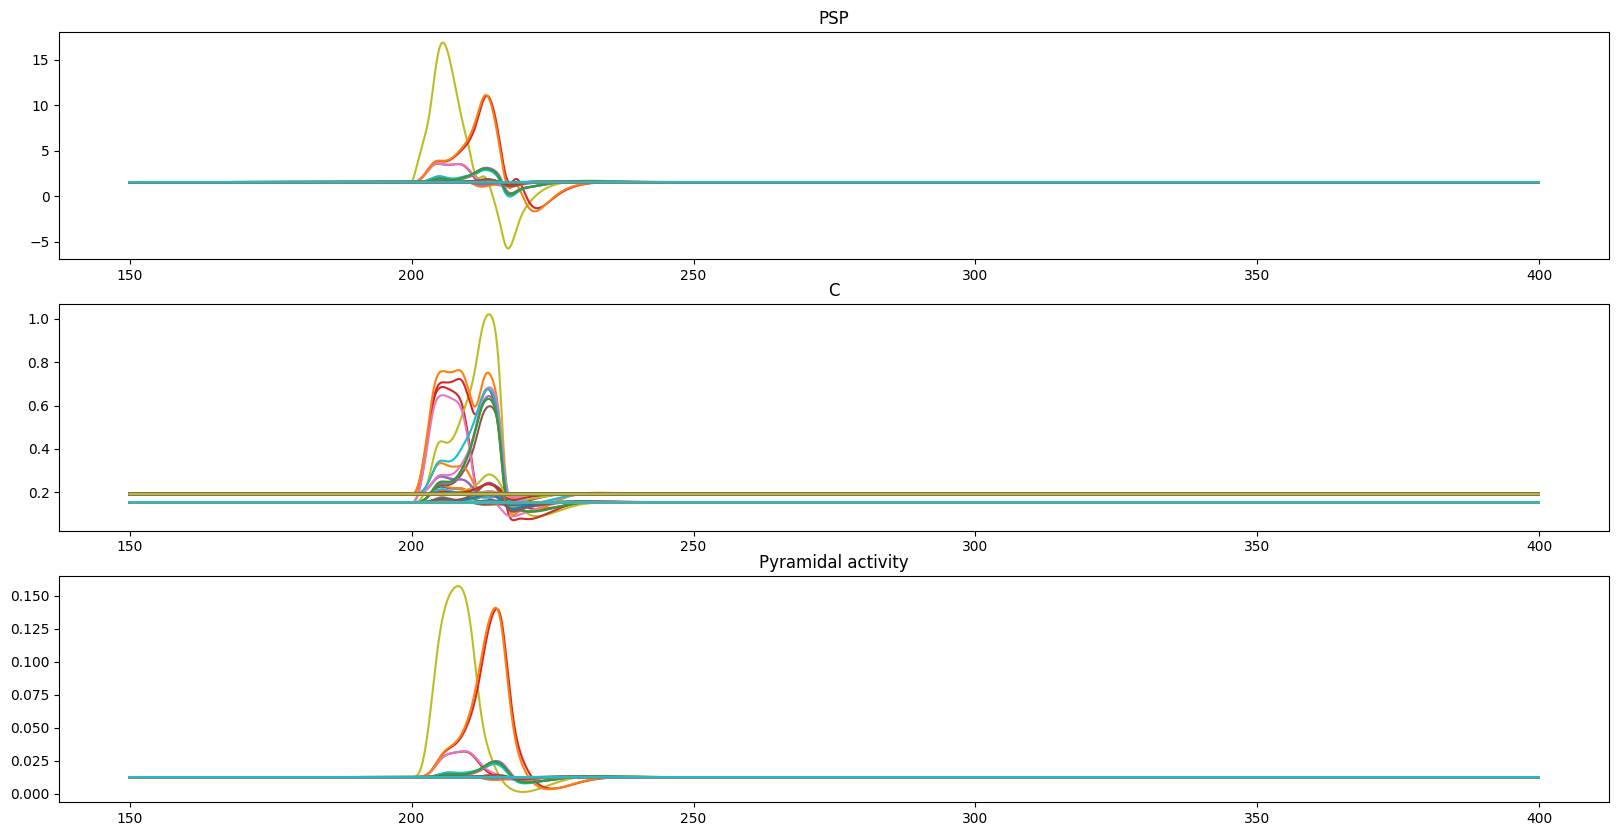

In [ ]:
PSP, C, y0 = hab_results
t = np.arange(PSP.shape[0])*0.1

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(20,10))
start = 150    # in [ms]
end   = 400

s_idx = int(start*10)
e_idx = int(end*10)
axs[0].plot(t[s_idx:e_idx], PSP[s_idx:e_idx,:])
axs[0].set_title("PSP")
#axs[0].legend(labels)

axs[1].plot(t[s_idx:e_idx], C[s_idx:e_idx,:])
axs[1].set_title("C")

axs[2].plot(t[s_idx:e_idx], y0[s_idx:e_idx,:])
axs[2].set_title("Pyramidal activity")

plt.show()

In [128]:
# rebuild connectivity
centres, labels, weights, lengths = generate_sphere_graph(1000)
speed    = np.array([3])
conn     = build_connectvitiy(weights, lengths, labels, centres, speed)

plot_graph_activity(conn, t[s_idx:e_idx], np.abs(PSP[s_idx:e_idx, :]))

Widget(value='<iframe src="http://localhost:35079/index.html?ui=P_0x712d6bae9e50_15&reconnect=auto" class="pyv…